In [1]:
from __future__ import annotations

import math
import random
from collections.abc import Callable, Collection, Sequence
from typing import Any, Protocol

import numpy as np
import matplotlib.pyplot as plt
from graphviz import Digraph

In [2]:
random.seed(42)

## 1. Intuition de la dérivée

Avant de coder quoi que ce soit, cette section revient sur la définition de
la dérivée : `f'(x) = lim h->0 [f(x+h) - f(x)] / h`. Plutôt que de la
dériver symboliquement à la main (personne ne fait ça pour un réseau de
neurones, l'expression aurait des milliers de termes), elle est estimée
**numériquement** avec un `h` tout petit.

In [3]:
def f(x: float) -> float:
    return 3 * x**2 - 4 * x + 5

In [4]:
f(3.0)

20.0

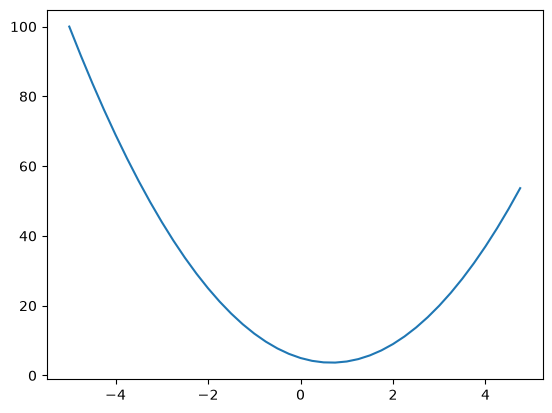

In [5]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [6]:
h = 0.000001
x = 2/3
(f(x + h) - f(x))/h

2.999378523327323e-06

## 2. Dérivée par rapport à plusieurs entrées

Même idée mais avec une fonction à 3 entrées `a, b, c -> d = a*b + c` :
chaque entrée est bougée une à la fois pour observer son influence
individuelle sur `d`. C'est exactement l'intuition nécessaire pour
comprendre le gradient d'un poids de réseau de neurones.

In [7]:
# les get more complex
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

4.0


In [8]:
def d_de(a: float, b: float, c: float) -> float:
    return a * b + c

In [9]:
pas: float = 1e-4
base_a: float = 2.0
base_b: float = -3.0
base_c: float = 10.0

reference: float = d_de(base_a, base_b, base_c)

print(f"Réference: {reference}")
print("influence de a sur d:", (d_de(base_a + pas, base_b, base_c) - reference) / pas)
print("influence de b sur d:", (d_de(base_a, base_b + pas, base_c) - reference) / pas)
print("influence de c sur d:", (d_de(base_a, base_b, base_c + pas) - reference) / pas)

Réference: 4.0
influence de a sur d: -3.000000000010772
influence de b sur d: 2.0000000000042206
influence de c sur d: 0.9999999999976694


## 3. La classe `Value` — étape 1 : juste un scalaire

Un réseau de neurones n'est rien d'autre qu'une expression mathématique
géante. Pour pouvoir un jour calculer ses dérivées automatiquement, il faut
d'abord un objet qui **enveloppe** un nombre.

In [10]:
class Value:
    """Étape 1 — simple conteneur autour d'un scalaire.

    À ce stade la classe ne sait rien faire d'autre que stocker un nombre et
    s'afficher lisiblement. Toutes les capacités (opérations, graphe, gradient)
    seront ajoutées dans les versions suivantes.
    """

    def __init__(self, data: float) -> None:
        """Enveloppe un scalaire Python.

        Args:
            data: Valeur numérique portée par ce nœud.
        """
        self.data: float = data

    def __repr__(self) -> str:
        return f"Value(data={self.data})"

In [11]:
print(Value(2.0))

Value(data=2.0)


In [12]:
a = Value(2.0)
b = Value(3)

In [13]:
# a + b

## 4. Étape 2 : additionner et multiplier des `Value`

`a + b` ne marche pas encore : Python ne sait pas additionner deux objets
`Value`. Il faut définir les méthodes spéciales `__add__` et `__mul__`.

In [14]:
class Value:
    """Étape 2 — le scalaire devient combinable avec `+` et `*`.

    Définir `__add__` et `__mul__` permet d'écrire `a + b` et `a * b` sur des
    objets. Le résultat est un nouveau `Value` : rien n'est encore mémorisé
    sur la manière dont il a été obtenu.
    """

    def __init__(self, data: float) -> None:
        """Enveloppe un scalaire Python.

        Args:
            data: Valeur numérique portée par ce nœud.
        """
        self.data: float = data

    def __repr__(self) -> str:
        return f"Value(data={self.data})"

    def __add__(self, other: Value) -> Value:
        """Additionne deux nœuds et renvoie un nouveau nœud."""
        return Value(self.data + other.data)

    def __mul__(self, other: Value) -> Value:
        """Multiplie deux nœuds et renvoie un nouveau nœud."""
        return Value(self.data * other.data)

In [15]:
print("a * b + c =", Value(2.0) * Value(-3.0) + Value(10.0))

a * b + c = Value(data=4.0)


## 5. Étape 3 : garder la trace du graphe (`_prev` et `_op`)

Pour pouvoir un jour remonter le graphe et calculer des gradients, chaque
`Value` doit se souvenir de **qui l'a produite** (`_prev`, ses enfants) et
**par quelle opération** (`_op`). Un attribut `label` est aussi ajouté,
uniquement pour la lisibilité des schémas.

In [16]:
class Value:
    """Étape 3 — chaque nœud mémorise le graphe d'expression qui l'a produit.

    Deux attributs privés suffisent : `_prev` (les nœuds enfants) et `_op`
    (le symbole de l'opération). C'est cette structure de graphe qu'on
    remontera ensuite pour propager les gradients.
    """

    def __init__(
        self,
        data: float,
        _children: tuple[Value, ...] = (),
        _op: str = "",
        label: str = "",
    ) -> None:
        """Crée un nœud du graphe d'expression.

        Args:
            data: Valeur numérique portée par ce nœud.
            _children: Nœuds ayant servi à produire celui-ci. Vide pour une
                feuille (une entrée ou un paramètre).
            _op: Symbole de l'opération dont ce nœud est le résultat
                (`"+"`, `"*"`, ...). Vide pour une feuille.
            label: Nom lisible du nœud, utilisé uniquement à l'affichage.
        """
        self.data: float = data
        self.label: str = label
        self._prev: set[Value] = set(_children)
        self._op: str = _op

    def __repr__(self) -> str:
        return f"Value(data={self.data})"

    def __add__(self, other: Value) -> Value:
        """Additionne deux nœuds en enregistrant le lien dans le graphe."""
        return Value(self.data + other.data, (self, other), "+")

    def __mul__(self, other: Value) -> Value:
        """Multiplie deux nœuds en enregistrant le lien dans le graphe."""
        return Value(self.data * other.data, (self, other), "*")

In [17]:
a = Value(2.0, label="a")
b = Value(-3.0, label="b")
c = Value(10.0, label="c")
e = a * b
e.label = "e"
d = e + c
d.label = "d"
print("d._prev =", d._prev)  # {e, c} : d se souvient de ses enfants
print("d._op   =", d._op)  # '+' : d se souvient de l'operation

d._prev = {Value(data=10.0), Value(data=-6.0)}
d._op   = +


## 6. Visualiser le graphe (Graphviz)

Une fonction `trace` / `draw_dot` permet de visualiser le graphe
d'expression avec Graphviz. Le rendu graphique est optionnel (il faut le
paquet `graphviz` **et** le binaire système `dot`) : si ce n'est pas
installé, le notebook se rabat sur un affichage texte.

In [18]:
class ExpressionNode(Protocol):
    data: float
    label: str
    _op: str
    _prev: Collection[Any]


def trace(root: ExpressionNode) -> tuple[set[ExpressionNode], set[tuple[ExpressionNode, ExpressionNode]]]:
    """Parcourt récursivement le graphe et en extrait nœuds et arêtes.

    Args:
        root: Nœud de sortie, point de départ du parcours vers les feuilles.

    Returns:
        Un couple `(nœuds, arêtes)`, où chaque arête est un couple
        `(enfant, parent)` orienté dans le sens du calcul.
    """
    nodes: set[ExpressionNode] = set()
    edges: set[tuple[ExpressionNode, ExpressionNode]] = set()

    def build(node: ExpressionNode) -> None:
        if node not in nodes:
            nodes.add(node)
            for child in node._prev:
                edges.add((child, node))
                build(child)

    build(root)
    return nodes, edges

trace(d)

({Value(data=-3.0),
  Value(data=-6.0),
  Value(data=10.0),
  Value(data=2.0),
  Value(data=4.0)},
 {(Value(data=-3.0), Value(data=-6.0)),
  (Value(data=-6.0), Value(data=4.0)),
  (Value(data=10.0), Value(data=4.0)),
  (Value(data=2.0), Value(data=-6.0))})

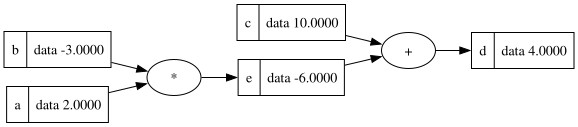

In [19]:
def draw_dot(root: ExpressionNode) -> Any:
    """Dessine le graphe d'expression, ou l'imprime en texte si Graphviz manque.

    Chaque nœud est affiché avec son label, sa valeur (`data`) et son gradient
    (`grad`, absent des premières versions de la classe et alors affiché à 0).

    Args:
        root: Nœud de sortie du graphe à représenter.

    Returns:
        L'objet `graphviz.Digraph` prêt à être affiché dans un notebook, ou
        `None` si `graphviz` n'est pas installé (le graphe est alors imprimé
        en texte sur la sortie standard).
    """
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"}) # LR = left to right
    nodes, edges = trace(root)
    for node in nodes:
        uid = str(id(node))
        dot.node(
            name=uid,
            label=f"{{ {node.label} | data {node.data:.4f}}}",
            shape="record",
        )
        if node._op:
            # nœud fictif représentant l'opération, uniquement pour la lisibilité
            dot.node(name=uid + node._op, label=node._op)
            dot.edge(uid + node._op, uid)
    for child, parent in edges:
        dot.edge(str(id(child)), str(id(parent)) + parent._op)
    return dot


draw_dot(d)

## 7. Étendre le graphe : `e`, `f`, `L`

Le graphe se complexifie encore un peu : `L = (a*b + c) * f`. `L` joue le
rôle de la « sortie » (dans un vrai réseau ce serait la loss) ; c'est sa
dérivée par rapport à tout le reste qui est recherchée.

L = Value(data=-8.0)


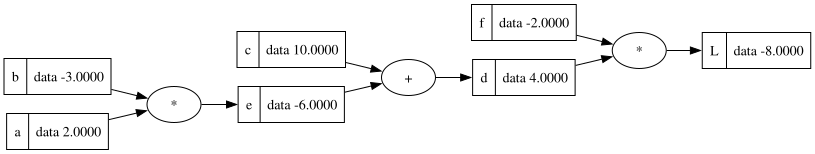

In [20]:
f = Value(-2.0, label="f")
L = d * f
L.label = "L"
print("L =", L)  # -8.0
draw_dot(L)

## 8. Rétropropagation MANUELLE

Un attribut `grad` est ajouté à la classe : la dérivée de la sortie finale
par rapport à ce nœud. Il démarre à `0.0`, ce qui se lit « ce nœud n'a pour
l'instant aucune influence connue sur la sortie ».

La dérivée de `L` par rapport à CHAQUE nœud est ensuite calculée à la main,
en partant de `L` et en remontant le graphe, en appliquant la **règle de la
chaîne** (*chain rule*) : `dz/dx = dz/dy * dy/dx`.

Analogie utile : une voiture va 2× plus vite qu'un vélo, un vélo va 4× plus
vite qu'un marcheur → la voiture va 2×4 = 8× plus vite que le marcheur. Les
taux de variation successifs se **multiplient**.

Les deux règles locales qui reviennent partout :

- nœud `+` : distribue le gradient tel quel à ses deux enfants (dérivée
  locale = 1 des deux côtés) ;
- nœud `*` : chaque enfant reçoit `gradient_sortie × valeur_de_l_autre`.

In [21]:
class Value:
    """Étape 4 — chaque nœud porte son gradient.

    Ajoute l'attribut `grad`, qui stockera la dérivée de la sortie finale du
    graphe par rapport à ce nœud. Il est ici encore rempli à la main, nœud par
    nœud ; l'automatisation viendra à l'étape 6 (`Value`).
    """

    def __init__(
        self,
        data: float,
        _children: tuple[Value, ...] = (),
        _op: str = "",
        label: str = "",
    ) -> None:
        """Crée un nœud du graphe, avec un gradient initialisé à zéro."""
        self.data: float = data
        self.grad: float = 0.0
        self.label: str = label
        self._prev: set[Value] = set(_children)
        self._op: str = _op

    def __repr__(self) -> str:
        return f"Value(data={self.data}, grad={self.grad})"

    def __add__(self, other: Value) -> Value:
        """Additionne deux nœuds en enregistrant le lien dans le graphe."""
        return Value(self.data + other.data, (self, other), "+")

    def __mul__(self, other: Value) -> Value:
        """Multiplie deux nœuds en enregistrant le lien dans le graphe."""
        return Value(self.data * other.data, (self, other), "*")

In [22]:
# on reconstruit le même graphe qu'à l'étape précédente, avec la nouvelle classe
a = Value(2.0, label="a")
b = Value(-3.0, label="b")
c = Value(10.0, label="c")
e = a * b
e.label = "e"
d = e + c
d.label = "d"
f = Value(-2.0, label="f")
L = d * f
L.label = "L"

In [23]:
# dL/dL = 1 : cas de base, si L bouge de h alors L bouge de h
L.grad = 1.0

In [24]:
# L = d * f  =>  dL/dd = f.data  et  dL/df = d.data
d.grad = f.data
f.grad = d.data

# d = e + c  =>  un '+' route le gradient tel quel vers ses deux enfants
e.grad = 1.0 * d.grad
c.grad = 1.0 * d.grad

# e = a * b  =>  chain rule : dL/da = dL/de * de/da = dL/de * b.data
a.grad = e.grad * b.data
b.grad = e.grad * a.data

print("a.grad =", a.grad)  # 6.0
print("b.grad =", b.grad)  # -4.0
print("c.grad =", c.grad)  # -2.0
print("d.grad =", d.grad)  # -2.0
print("e.grad =", e.grad)  # -2.0
print("f.grad =", f.grad)  # 4.0

a.grad = 6.0
b.grad = -4.0
c.grad = -2.0
d.grad = -2.0
e.grad = -2.0
f.grad = 4.0


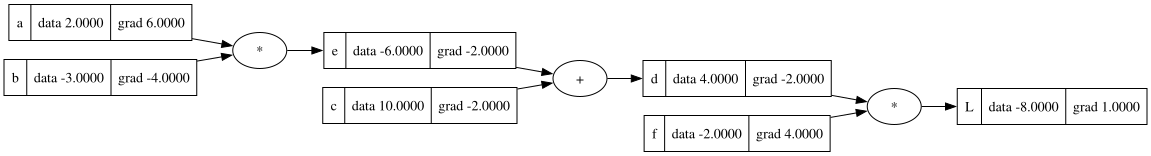

In [25]:
def draw_dot(root: ExpressionNode) -> Any:
    """Version mise à jour de `draw_dot` : affiche aussi le gradient de chaque nœud."""
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"}) # LR = left to right
    nodes, edges = trace(root)
    for node in nodes:
        uid = str(id(node))

        dot.node(
            name=uid,
            label=f"{{ {node.label} | data {node.data:.4f} | grad {node.grad:.4f}}}",
            shape="record",
        )
        if node._op:
            # nœud fictif représentant l'opération, uniquement pour la lisibilité
            dot.node(name=uid + node._op, label=node._op)
            dot.edge(uid + node._op, uid)
    for child, parent in edges:
        dot.edge(str(id(child)), str(id(parent)) + parent._op)
    return dot
draw_dot(L)

### Vérification numérique (*gradient check*)

Chaque gradient calculé à la main est vérifié en perturbant l'entrée
concernée de `h` et en mesurant de combien `L` a bougé.

In [26]:
def L_de(a: float, b: float, c: float, f: float) -> float:
    return (a * b + c) * f

h: float = 1e-4
L_reference: float = L_de(2.0, -3.0, 10.0, -2.0)
print("dL/da numerique :", (L_de(2.0 + h, -3.0, 10.0, -2.0) - L_reference) / h, "(attendu ~6)")
print("dL/dc numerique :", (L_de(2.0, -3.0, 10.0 + h, -2.0) - L_reference) / h, "(attendu ~-2)")

dL/da numerique : 6.000000000021544 (attendu ~6)
dL/dc numerique : -1.9999999999953388 (attendu ~-2)


### Une "étape d'optimisation"

En poussant chaque entrée dans la direction de son gradient, `L` doit
augmenter (la pente est suivie). C'est le principe même de la descente de
gradient, automatisée plus loin — au signe près, puisqu'il s'agira alors de
*minimiser* une loss plutôt que de maximiser `L`.

In [27]:
taille_du_pas: float = 0.01
print("L avant :", L.data)
print(
    "L apres un pas dans le sens du gradient :",
    L_de(
        a.data + taille_du_pas * a.grad,
        b.data + taille_du_pas * b.grad,
        c.data + taille_du_pas * c.grad,
        f.data + taille_du_pas * f.grad,
    ),
)

L avant : -8.0
L apres un pas dans le sens du gradient : -7.286496


Valeur négative donc il va vers 0

## 9. Rétropropagation à travers un neurone artificiel

Modèle mathématique d'un neurone : entrées `x1, x2`, poids `w1, w2`, biais
`b`. La cellule calcule `n = w1*x1 + w2*x2 + b`, puis passe `n` dans une
fonction d'activation, ici `tanh` (une fonction *squashing* qui écrase la
sortie entre -1 et 1).

`tanh` a besoin de l'exponentielle, pas encore disponible ici. Elle est
d'abord ajoutée comme opération **composite** directement dans la classe
(sans être décomposée) : ce qui compte, c'est de connaître sa dérivée locale
`1 - tanh(x)²`, peu importe le niveau d'abstraction choisi.

In [28]:
class Value:
    """Étape 5 — ajout de l'activation `tanh` comme opération composite.

    Démontre qu'une opération n'a pas besoin d'être atomique : tant qu'on sait
    écrire sa dérivée locale, elle peut entrer telle quelle dans le graphe.
    """

    def __init__(
        self,
        data: float,
        _children: tuple[Value, ...] = (),
        _op: str = "",
        label: str = "",
    ) -> None:
        """Crée un nœud du graphe, avec un gradient initialisé à zéro."""
        self.data: float = data
        self.grad: float = 0.0
        self.label: str = label
        self._prev: set[Value] = set(_children)
        self._op: str = _op

    def __repr__(self) -> str:
        return f"Value(data={self.data}, grad={self.grad})"

    def __add__(self, other: Value) -> Value:
        """Additionne deux nœuds en enregistrant le lien dans le graphe."""
        return Value(self.data + other.data, (self, other), "+")

    def __mul__(self, other: Value) -> Value:
        """Multiplie deux nœuds en enregistrant le lien dans le graphe."""
        return Value(self.data * other.data, (self, other), "*")

    def tanh(self) -> Value:
        """Applique la tangente hyperbolique, qui écrase la sortie dans ]-1, 1[.

        Returns:
            Un nouveau nœud portant `tanh(self.data)`.
        """
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        return Value(t, (self,), "tanh")

o = Value(data=0.7071067811865476, grad=0.0)


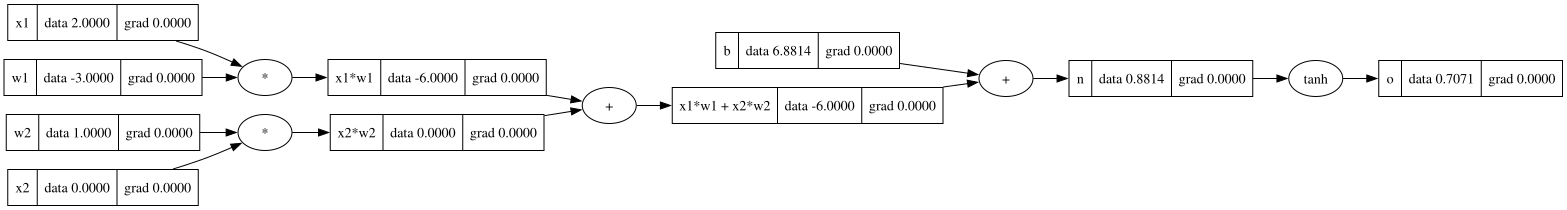

In [29]:
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
b = Value(6.8813735870195432, label="b")  # valeur choisie pour obtenir des gradients « ronds »

x1w1 = x1 * w1
x1w1.label = "x1*w1"
x2w2 = x2 * w2
x2w2.label = "x2*w2"
somme_produits = x1w1 + x2w2
somme_produits.label = "x1*w1 + x2*w2"
n = somme_produits + b
n.label = "n"
o = n.tanh()
o.label = "o"
print("o =", o)  # ~0.7071
draw_dot(o)

w2.grad = 0.0
x1.grad = -1.4999999999999996
w1.grad = 0.9999999999999998


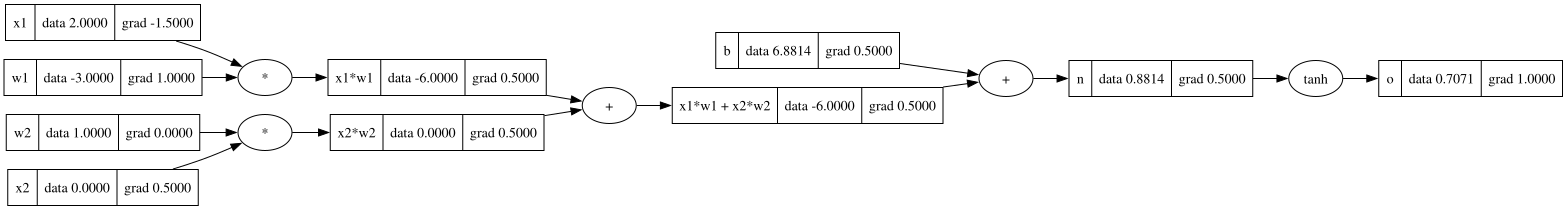

In [30]:
o.grad = 1.0
n.grad = (1 - o.data**2) * o.grad  # dérivée locale de tanh

somme_produits.grad = 1.0 * n.grad  # nœud '+' : distribue
b.grad = 1.0 * n.grad

x1w1.grad = 1.0 * somme_produits.grad
x2w2.grad = 1.0 * somme_produits.grad

x1.grad = w1.data * x1w1.grad  # nœud '*' : chain rule
w1.grad = x1.data * x1w1.grad
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

print("w2.grad =", w2.grad)  # 0.0 : x2 vaut 0, ce poids n'a aucune influence ici
print("x1.grad =", x1.grad)  # -1.5
print("w1.grad =", w1.grad)  # 1.0

draw_dot(o)

## 10. Automatiser la rétropropagation : `_backward`

Faire ça à la main pour chaque opération devient ridicule dès que le graphe
grandit. Chaque nœud stocke désormais une petite fonction `_backward()` qui
sait faire elle-même son bout de chain rule : « à partir de mon propre
gradient, comment je le distribue à mes enfants ? ».

⚠️ Bug volontaire conservé à cette étape (comme dans la vidéo) : `=` est
utilisé au lieu de `+=`. Il sera mis en évidence à l'étape 11.

In [31]:
class Value:
    """Étape 6 — chaque nœud sait propager son gradient vers ses enfants.

    Chaque opération construit une closure `_backward` qui applique la règle de
    la chaîne localement. Il ne reste plus qu'à appeler ces closures dans le bon
    ordre (cf. `build_topo_ordre`).

    Warning:
        Cette version contient un bug volontaire : les gradients sont **écrasés**
        (`=`) au lieu d'être **accumulés** (`+=`). Il est démontré puis corrigé
        à l'étape suivante.
    """

    def __init__(
        self,
        data: float,
        _children: tuple[Value, ...] = (),
        _op: str = "",
        label: str = "",
    ) -> None:
        """Crée un nœud du graphe, sans effet de bord au backward par défaut."""
        self.data: float = data
        self.grad: float = 0.0
        self.label: str = label
        self._prev: set[Value] = set(_children)
        self._op: str = _op
        # une feuille n'a rien à propager : sa closure ne fait rien
        self._backward: Callable[[], None] = lambda: None

    def __repr__(self) -> str:
        return f"Value(label={self.label}, data={self.data}, grad={self.grad})"

    def __add__(self, other: Value) -> Value:
        """Additionne deux nœuds et attache la règle de dérivation de `+`."""
        out = Value(self.data + other.data, (self, other), "+")

        def _backward() -> None:
            # BUG : écrase le gradient au lieu de l'accumuler (corrigé étape 11)
            self.grad = 1.0 * out.grad
            other.grad = 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other: Value) -> Value:
        """Multiplie deux nœuds et attache la règle de dérivation de `*`."""
        out = Value(self.data * other.data, (self, other), "*")

        def _backward() -> None:
            self.grad = other.data * out.grad
            other.grad = self.data * out.grad

        out._backward = _backward
        return out

    def tanh(self) -> Value:
        """Applique `tanh` et attache sa règle de dérivation `1 - tanh(x)²`."""
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self,), "tanh")

        def _backward() -> None:
            self.grad = (1 - t**2) * out.grad

        out._backward = _backward
        return out

In [32]:
def build_topo_ordre(root: Value) -> list[Value]:
    """Trie topologiquement le graphe qui aboutit à `root`.

    Un nœud n'est ajouté à la liste qu'une fois tous ses enfants ajoutés. En
    parcourant la liste **à l'envers**, on est donc certain de traiter un nœud
    avant ses enfants, ce qu'exige la rétropropagation.

    Args:
        root: Nœud de sortie du graphe.

    Returns:
        Les nœuds du graphe, des feuilles vers `root`.
    """
    visited: set[Value] = set()
    topo: list[Value] = []

    def build(node: Value) -> None:
        if node not in visited:
            visited.add(node)
            for child in node._prev:
                build(child)
            topo.append(node)

    build(root)
    return topo

### Reconstruire le neurone et appeler `_backward()` dans l'ordre

Le forward pass du neurone est rejoué avec cette nouvelle classe, puis le
gradient est propagé nœud par nœud en partant de `o`, dans l'ordre
topologique inversé.

In [33]:
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
b = Value(6.8813735870195432, label="b")

n = x1 * w1 + x2 * w2 + b
o = n.tanh()

o.grad = 1.0
for node in reversed(build_topo_ordre(o)):
    node._backward()

print("w2.grad =", w2.grad, " x1.grad =", x1.grad, " w1.grad =", w1.grad)

w2.grad = 0.0  x1.grad = -1.4999999999999996  w1.grad = 0.9999999999999998


In [34]:
build_topo_ordre(o)

[Value(label=b, data=6.881373587019543, grad=0.4999999999999999),
 Value(label=w1, data=-3.0, grad=0.9999999999999998),
 Value(label=x1, data=2.0, grad=-1.4999999999999996),
 Value(label=, data=-6.0, grad=0.4999999999999999),
 Value(label=w2, data=1.0, grad=0.0),
 Value(label=x2, data=0.0, grad=0.4999999999999999),
 Value(label=, data=0.0, grad=0.4999999999999999),
 Value(label=, data=-6.0, grad=0.4999999999999999),
 Value(label=, data=0.8813735870195432, grad=0.4999999999999999),
 Value(label=, data=0.7071067811865476, grad=1.0)]

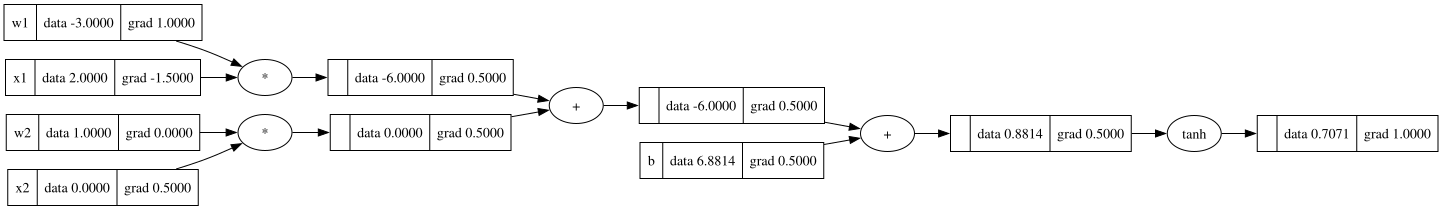

In [35]:
draw_dot(o)

## 11. Le bug d'accumulation des gradients

Si un même nœud est utilisé PLUSIEURS FOIS dans une expression (ex. `y = x + x`),
la version `=` ci-dessus écrase le gradient au lieu de l'additionner.
Démonstration du bug :

In [36]:
x_reutilise = Value(3.0, label="x")
y_bug = x_reutilise + x_reutilise  # x est utilisé deux fois
y_bug.grad = 1.0
for node in reversed(build_topo_ordre(y_bug)):
    node._backward()
print("BUG : x.grad =", x_reutilise.grad, "(devrait valoir 2.0, la derivee de x+x)")

BUG : x.grad = 1.0 (devrait valoir 2.0, la derivee de x+x)


**Correction** : les `=` sont remplacés par des `+=` dans tous les
`_backward`. Comme `grad` démarre toujours à `0.0`, chaque contribution vient
simplement s'additionner par-dessus les précédentes — ce qui correspond
exactement à la règle de dérivation multivariable (les contributions de
plusieurs chemins s'additionnent).

C'est aussi l'occasion de compléter le jeu d'opérations : constantes,
opérateurs inversés (`2 * a`), `exp`, puissance, soustraction et division.

In [37]:
class Value:
    """Scalaire différentiable : nœud d'un graphe d'expression avec autograd.

    Version finale et corrigée, équivalente au `Value` de `micrograd`. Chaque
    instance mémorise sa valeur (`data`), le gradient de la sortie finale par
    rapport à elle (`grad`), et la manière dont elle a été produite (`_prev`,
    `_op`, `_backward`).

    Les opérateurs arithmétiques usuels sont surchargés : construire une
    expression Python construit simultanément le graphe de calcul. Appeler
    `backward()` sur le nœud de sortie remplit le `grad` de tout le graphe.

    Example:
        >>> a = Value(2.0)
        >>> b = Value(-3.0)
        >>> c = a * b + 1
        >>> c.backward()
        >>> a.grad  # dc/da = b
        -3.0

    Attributes:
        data: Valeur numérique portée par ce nœud.
        grad: Dérivée de la sortie du graphe par rapport à ce nœud. Vaut `0.0`
            tant que `backward()` n'a pas été appelé.
        label: Nom lisible, utilisé uniquement à l'affichage.
    """

    def __init__(
        self,
        data: float,
        _children: tuple[Value, ...] = (),
        _op: str = "",
        label: str = "",
    ) -> None:
        """Crée un nœud du graphe d'expression."""
        self.data: float = data
        self.grad: float = 0.0
        self.label: str = label
        self._prev: set[Value] = set(_children)
        self._op: str = _op
        self._backward: Callable[[], None] = lambda: None

    def __repr__(self) -> str:
        return f"Value(data={self.data}, grad={self.grad})"

    def __add__(self, other: Value | float) -> Value:
        """Additionne ce nœud à un autre nœud ou à une constante."""
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")

        def _backward() -> None:
            # dérivée locale d'une somme : 1 de chaque côté
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __radd__(self, other: float) -> Value:
        """Gère `1 + a`, que Python redirige ici faute de savoir le faire."""
        return self + other

    def __mul__(self, other: Value | float) -> Value:
        """Multiplie ce nœud par un autre nœud ou par une constante."""
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")

        def _backward() -> None:
            # dérivée locale d'un produit : la valeur de l'autre opérande
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __rmul__(self, other: float) -> Value:
        """Gère `2 * a`, que Python redirige ici faute de savoir le faire."""
        return self * other

    def __pow__(self, other: float) -> Value:
        """Élève ce nœud à une puissance constante.

        Args:
            other: Exposant, obligatoirement un nombre (pas un `Value`) : la
                dérivée d'un exposant variable demanderait une autre formule.

        Returns:
            Un nouveau nœud portant `self.data ** other`.

        Raises:
            AssertionError: Si l'exposant n'est pas un `int` ou un `float`.
        """
        assert isinstance(other, (int, float)), "seules les puissances constantes sont gerees"
        out = Value(self.data**other, (self,), f"**{other}")

        def _backward() -> None:
            # règle de puissance : d/dx xⁿ = n·xⁿ⁻¹
            self.grad += (other * self.data ** (other - 1)) * out.grad

        out._backward = _backward
        return out

    def __neg__(self) -> Value:
        """Renvoie l'opposé, exprimé comme une multiplication par -1."""
        return self * -1

    def __sub__(self, other: Value | float) -> Value:
        """Soustrait, exprimé comme l'addition d'un opposé."""
        return self + (-other)

    def __rsub__(self, other: float) -> Value:
        """Gère `1 - a`, que Python redirige ici faute de savoir le faire."""
        return (-self) + other

    def __truediv__(self, other: Value | float) -> Value:
        """Divise, exprimé comme `a / b == a * b⁻¹`."""
        return self * other**-1

    def exp(self) -> Value:
        """Applique l'exponentielle.

        Returns:
            Un nouveau nœud portant `exp(self.data)`. Sa dérivée locale est
            `exp(x)`, c'est-à-dire la sortie elle-même.
        """
        out = Value(math.exp(self.data), (self,), "exp")

        def _backward() -> None:
            self.grad += out.data * out.grad

        out._backward = _backward
        return out

    def tanh(self) -> Value:
        """Applique la tangente hyperbolique, qui écrase la sortie dans ]-1, 1[.

        Returns:
            Un nouveau nœud portant `tanh(self.data)`. Sa dérivée locale est
            `1 - tanh(x)²`.
        """
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self,), "tanh")

        def _backward() -> None:
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward
        return out

    def backward(self) -> None:
        """Rétropropage le gradient depuis ce nœud jusqu'à toutes les feuilles.

        Trie le graphe topologiquement, initialise `self.grad` à `1.0` (dérivée
        de la sortie par rapport à elle-même), puis applique la règle de la
        chaîne nœud par nœud en remontant le graphe.

        Note:
            Les gradients sont **accumulés**. Avant de relancer un `backward()`
            sur un graphe dont les paramètres sont réutilisés (une boucle
            d'entraînement, typiquement), il faut les remettre à zéro — d'où
            `Module.zero_grad`.
        """
        topo: list[Value] = []
        visited: set[Value] = set()

        def build(node: Value) -> None:
            if node not in visited:
                visited.add(node)
                for child in node._prev:
                    build(child)
                topo.append(node)

        build(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [38]:
x_final = Value(3.0, label="x")
y_final = x_final + x_final
y_final.backward()
print("x.grad =", x_final.grad, "(2.0, correct)")

x.grad = 2.0 (2.0, correct)


## 12. Décomposer `tanh` pour prouver l'équivalence

`tanh(x) = (e^2x - 1) / (e^2x + 1)` est réécrit avec les briques `exp`, `+`,
`-`, `/` tout juste ajoutées, au lieu d'utiliser la méthode `.tanh()` toute
faite. Si tout est cohérent, le forward pass ET tous les gradients doivent
être strictement identiques. C'est la démonstration que le niveau
d'abstraction d'une opération n'a aucune importance, tant que sa dérivée
locale est correcte.

In [39]:
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
b = Value(6.8813735870195432, label="b")

n = x1 * w1 + x2 * w2 + b
exp_2n = (2 * n).exp()
o = (exp_2n - 1) / (exp_2n + 1)  # tanh(n) redémontré à partir de exp, +, -, /
o.backward()

print("o.data  =", o.data)  # ~0.7071, identique à la version .tanh()
print("x1.grad =", x1.grad)  # -1.5
print("w1.grad =", w1.grad)  # 1.0
print("w2.grad =", w2.grad)  # 0.0

o.data  = 0.7071067811865477
x1.grad = -1.5
w1.grad = 1.0
w2.grad = 0.0


## 13. Comparaison avec PyTorch

Même neurone, mais avec de vrais `torch.Tensor`. Optionnel : ne s'exécute que
si `torch` est installé. Les valeurs et les gradients doivent être identiques
à ceux de micrograd — micrograd suit fidèlement l'API et la logique de
PyTorch, simplement avec des scalaires au lieu de tenseurs.

In [40]:
import torch

x1 = torch.tensor([2.0], dtype=torch.double, requires_grad=True)
x2 = torch.tensor([0.0], dtype=torch.double, requires_grad=True)
w1 = torch.tensor([-3.0], dtype=torch.double, requires_grad=True)
w2 = torch.tensor([1.0], dtype=torch.double, requires_grad=True)
b = torch.tensor([6.8813735870195432], dtype=torch.double, requires_grad=True)

o = torch.tanh(x1 * w1 + x2 * w2 + b)
o.backward()

print("PyTorch o       =", o.item())
print("PyTorch x1.grad =", x1.grad.item())
print("PyTorch w1.grad =", w1.grad.item())

PyTorch o       = 0.7071067811865476
PyTorch x1.grad = -1.4999999999999998
PyTorch w1.grad = 0.9999999999999999


## 14. Construire le réseau de neurones : `Neuron`, `Layer`, `MLP`

L'API de PyTorch (`Module`, `__call__`) est suivie pour construire un réseau
complet à partir de la brique `Value` :

- un **`Neuron`** a des poids et un biais aléatoires, et calcule `tanh(w·x + b)` ;
- une **`Layer`** est une liste de neurones indépendants ;
- un **`MLP`** (*Multi-Layer Perceptron*) enchaîne plusieurs `Layer`.

In [41]:
class Module:
    """Classe de base des briques du réseau, calquée sur `torch.nn.Module`.

    Fournit la gestion des paramètres entraînables. Chaque sous-classe doit
    redéfinir `parameters()` ; `zero_grad()` en découle automatiquement.
    """

    def parameters(self) -> list[Value]:
        """Liste les paramètres entraînables de la brique.

        Returns:
            Les `Value` dont `data` sera ajusté par la descente de gradient.
            Vide par défaut : chaque sous-classe redéfinit cette méthode.
        """
        return []

    def zero_grad(self) -> None:
        """Remet à zéro le gradient de tous les paramètres.

        À appeler avant chaque `backward()` : les closures `_backward`
        accumulent les gradients avec `+=`, ils doivent donc repartir de zéro à
        chaque itération d'entraînement.
        """
        for parametre in self.parameters():
            parametre.grad = 0.0

In [42]:
class Neuron(Module):
    """Neurone unique : `tanh(w·x + b)`.

    Les poids et le biais sont tirés aléatoirement dans `[-1, 1]` à la
    construction, puis ajustés par la descente de gradient.
    """

    def __init__(self, nin: int) -> None:
        """Initialise un neurone à `nin` entrées.

        Args:
            nin: Nombre d'entrées du neurone, donc nombre de poids.
        """
        self.w: list[Value] = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b: Value = Value(random.uniform(-1, 1))

    def __call__(self, x: Sequence[Value | float]) -> Value:
        """Calcule la sortie du neurone pour une entrée donnée.

        Args:
            x: Entrées du neurone, de même longueur que `self.w`.

        Returns:
            L'activation `tanh(w·x + b)`, nœud du graphe d'expression.
        """
        # équivalent du `sum(..., start=self.b)` de la vidéo, écrit explicitement
        activation = self.b
        for poids, entree in zip(self.w, x):
            activation = activation + poids * entree
        return activation.tanh()

    def parameters(self) -> list[Value]:
        """Renvoie les poids suivis du biais."""
        return self.w + [self.b]

In [43]:
class Layer(Module):
    """Couche de neurones évalués indépendamment sur la même entrée."""

    def __init__(self, nin: int, nout: int) -> None:
        """Initialise une couche entièrement connectée.

        Args:
            nin: Nombre d'entrées reçues par chaque neurone.
            nout: Nombre de neurones de la couche, donc de sorties.
        """
        self.neurons: list[Neuron] = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x: Sequence[Value | float]) -> list[Value]:
        """Évalue tous les neurones de la couche sur la même entrée.

        Args:
            x: Entrées de la couche.

        Returns:
            Une sortie par neurone.
        """
        return [neurone(x) for neurone in self.neurons]

    def parameters(self) -> list[Value]:
        """Renvoie les paramètres de tous les neurones de la couche."""
        return [p for neurone in self.neurons for p in neurone.parameters()]

In [44]:
class MLP(Module):
    """Perceptron multicouche : des `Layer` enchaînées séquentiellement."""

    def __init__(self, nin: int, nouts: Sequence[int]) -> None:
        """Initialise le réseau à partir des tailles de couches.

        Args:
            nin: Dimension de l'entrée du réseau.
            nouts: Nombre de neurones de chaque couche, dans l'ordre. Par
                exemple `[4, 4, 1]` crée deux couches cachées de 4 neurones
                suivies d'une couche de sortie à 1 neurone.
        """
        tailles = [nin, *nouts]
        self.layers: list[Layer] = [Layer(tailles[i], tailles[i + 1]) for i in range(len(nouts))]

    def __call__(self, x: Sequence[Value | float]) -> Value | list[Value]:
        """Propage une entrée à travers toutes les couches.

        Args:
            x: Entrée du réseau, de dimension `nin`.

        Returns:
            La liste des sorties de la dernière couche, ou directement l'unique
            sortie si la couche finale ne contient qu'un neurone. La vidéo place
            ce déballage dans `Layer` ; le faire ici garde des types plus simples.
        """
        sorties: list[Value] = self.layers[0](x)
        for layer in self.layers[1:]:
            sorties = layer(sorties)
        return sorties[0] if len(sorties) == 1 else sorties

    def parameters(self) -> list[Value]:
        """Renvoie les paramètres de toutes les couches du réseau."""
        return [p for layer in self.layers for p in layer.parameters()]

In [45]:
# 3 entrées -> deux couches cachées de 4 neurones -> 1 sortie
modele_demo = MLP(3, [4, 4, 1])
print("sortie du MLP sur un exemple :", modele_demo([2.0, 3.0, -1.0]))
print("nombre total de parametres   :", len(modele_demo.parameters()))

sortie du MLP sur un exemple : Value(data=0.6994093620224068, grad=0.0)
nombre total de parametres   : 41


## 15. Entraîner le réseau sur un petit dataset

4 exemples, classifieur binaire simple. La **loss** mesure l'écart entre les
prédictions et les cibles : plus elle est basse, mieux le réseau prédit.

In [ ]:
def squared_error_loss(predictions: Sequence[Value], cibles: Sequence[float]) -> Value:
    """Somme des carrés des écarts entre prédictions et cibles.

    Args:
        predictions: Sorties du réseau.
        cibles: Valeurs attendues, dans le même ordre que `predictions`.

    Returns:
        Un nœud `Value` valant `Σ (prédiction - cible)²`, sur lequel appeler
        `backward()`. Élever au carré garantit une contribution positive quel
        que soit le sens de l'erreur, et nulle uniquement si la prédiction est
        exacte.
    """
    total = Value(0.0)
    for prediction, cible in zip(predictions, cibles):
        total = total + (prediction - cible) ** 2
    return total

In [47]:
xs: list[list[float]] = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys: list[float] = [1.0, -1.0, -1.0, 1.0]  # cibles souhaitées

In [48]:
predictions = []
for x in xs:
    sortie = modele_demo(x)
    predictions.append(sortie)

print("predictions avant entrainement :", [round(p.data, 3) for p in predictions])
print("loss avant entrainement        :", squared_error_loss(predictions, ys).data)

predictions avant entrainement : [0.699, 0.503, 0.693, 0.876]
loss avant entrainement        : 5.230517512042234


### Bug classique : oublier `zero_grad`

Sans remise à zéro des gradients avant chaque nouveau `backward()`, ils
**s'accumulent** d'une itération sur l'autre (tous les `_backward` font
`+=`). Le pas de descente devient alors bien plus grand que le
`learning_rate` annoncé. C'est l'un des bugs les plus fréquents en deep
learning ; ici le problème est si simple que le réseau converge quand même,
ce qui rend le bug d'autant plus sournois.

In [49]:
modele_bugue = MLP(3, [4, 4, 1])
for etape in range(3):
    predictions = [modele_bugue(x) for x in xs]
    loss = squared_error_loss(predictions, ys)
    loss.backward()  # aucun zero_grad : les gradients s'additionnent d'une etape a l'autre
    for parametre in modele_bugue.parameters():
        parametre.data -= 0.01 * parametre.grad
    print(f"[BUG] etape {etape} loss={loss.data:.4f}")

[BUG] etape 0 loss=5.3262
[BUG] etape 1 loss=5.0231
[BUG] etape 2 loss=4.4804


### Boucle d'entraînement correcte

`zero_grad()` avant chaque `backward()`. La descente de loss est
**régulière**, contrairement à la version buguée ci-dessus.

Le signe `-=` (et non `+=`) est essentiel : le gradient pointe dans la
direction où la loss **augmente**, donc pour la **minimiser**, l'avancée se
fait dans la direction opposée.

In [50]:
modele = MLP(3, [4, 4, 1])
learning_rate: float = 0.05
nb_etapes: int = 20

for etape in range(nb_etapes):
    # forward pass : prédictions puis loss
    predictions = [modele(x) for x in xs]
    loss = squared_error_loss(predictions, ys)

    # backward pass : gradients remis à zéro, puis rétropropagés
    modele.zero_grad()
    loss.backward()

    # update : un pas de descente de gradient sur chaque paramètre
    for parametre in modele.parameters():
        parametre.data -= learning_rate * parametre.grad

    print(f"etape {etape:2d}  loss={loss.data:.6f}")

print("\npredictions finales :", [round(modele(x).data, 4) for x in xs])
print("cibles              :", ys)

etape  0  loss=4.660888
etape  1  loss=3.796741
etape  2  loss=3.178855
etape  3  loss=2.420059
etape  4  loss=1.577479
etape  5  loss=0.805743
etape  6  loss=0.380218
etape  7  loss=0.227581
etape  8  loss=0.160810
etape  9  loss=0.123968
etape 10  loss=0.100686
etape 11  loss=0.084657
etape 12  loss=0.072957
etape 13  loss=0.064045
etape 14  loss=0.057034
etape 15  loss=0.051378
etape 16  loss=0.046720
etape 17  loss=0.042818
etape 18  loss=0.039504
etape 19  loss=0.036655

predictions finales : [0.9493, -0.9101, -0.8984, 0.8851]
cibles              : [1.0, -1.0, -1.0, 1.0]
